# Stage 1.5: geometry + per-face graphlet degree vectors

Choose graphlets with **2–4 nodes (15 node orbits)** or **2–5 nodes (73 node orbits)**. Concatenate each face's orbit-count vector with its CNN geometry embedding. Choose frozen CNN or joint CNN + classifier. No message passing and no graph-level kernel/SVM in this face-classification experiment.

Course references: `notebooks/05_Shallow_Learning/code01_solution.ipynb` (node-orbit counts, graph-size normalization, train-only standardization) and `code02_solution.ipynb` (canonical bit-mask isomorphism lookup). Lab 01 samples 4-node subsets; we count connected induced subsets exactly, exploiting these small CAD graphs and caching results. Five-node orbits extend the same definition. Orbits 0–14 follow the tutorial; 15–72 are in deterministic rooted-canonical-mask order, not standard ORCA numbering.

The graphlet graph is a **simple undirected graph**: collapse parallel edges and remove self-loops, as in the tutorial. Geometry is unchanged. Both modes start from the same final baseline CNN, with the same seeded classifier initialization for a given feature width. Training is not executed by notebook preparation.

The dimensions 15 and 73 count node roles, rather than the 9/30 connected graphlet types (8/29 if the single edge is excluded).

Final prediction exports include ordered sample IDs, per-row sample indices and zero-based graph face indices. These are checked against annotation labels; STEP viewer face identity is a separate mapping.


In [1]:
import os
os.environ["DGLBACKEND"] = "pytorch"

import csv
import hashlib
import json
from pathlib import Path

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

from uvnet_project.checkpointing import (
    seed_everything, save_training_checkpoint, load_training_checkpoint,
)
from uvnet_project.face_cnn import FaceCNN
from uvnet_project.classifier import Classifier
from uvnet_project.graphlets import graphlet_degree_vectors, orbit_catalog
from uvnet_project.load_mfcad import DATA_DIR, _load_sample, _load_splits
from uvnet_project.evaluation import evaluate

from uvnet_project.geometry_graphlet import FaceGraphletBatch, GeometryGraphletClassifier


## Reproducibility and epoch-boundary resume

Set `seed` and `resume_checkpoint` in the settings cell. Fresh runs seed Python, NumPy, Torch CPU/CUDA before initializing weights and again when starting a fresh training run. The training cell creates a fresh model when `resume_checkpoint=None`.

After **every completed epoch**, `epoch_NNN/model_weights.pt` contains model weights; `epoch_NNN/checkpoint.pt` contains weights, optimizer, AMP scaler where used, seed, Python/NumPy/Torch CPU/CUDA RNG states, histories and configuration. Checkpoints are written atomically. Graphlet checkpoints include the CNN state, baseline hash and training-only normalization statistics. Retain the input caches for resume.

To resume: restart the kernel, set `resume_checkpoint` to the desired `checkpoint.pt`, run preparation cells, then the training cell. Set `num_epochs` to the **total target**, e.g. 20 to continue epoch 10 through epoch 20. Resume restores RNG states immediately before the epoch loop, rather than resetting the seed each epoch. Loss curves and step counts continue from the stored histories. A partial epoch is rerun from the most recent completed checkpoint. The same mode-specific run folder is reused. Resume rejects a different mode; 

Use the same dataset order, cached features, software, GPU and training settings for reproducible replay. Deterministic settings disable cuDNN autotuning and TF32; restart the kernel before using them if CUDA was already initialized. Existing checkpoints created before this change lack RNG states: they can supply weights, but cannot provide exact trajectory resume. Training has not been started by these edits.


## Settings

Change `max_graphlet_nodes` between 4 and 5 and `training_mode` between `"frozen"` and `"joint"`, then rerun from the top. Each combination has a separate results folder. Defaults: 20 epochs, 128 solids per batch, Adam learning rate 0.001. The classifier hidden width matches the baseline; input width is 64 + 15 or 64 + 73 with the default geometry embedding.

Validation uses the official validation split; test is not loaded. The checkpoint path must point to the completed geometry-only baseline. All four combinations can be run sequentially by changing settings. Nothing runs all experiments automatically.


In [27]:
seed = 0
deterministic = True
# None starts a new seeded run. To resume, set the completed epoch checkpoint:
# resume_checkpoint = DATA_DIR.parent.parent / "results/graphlet4_frozen_run_01/epoch_010/checkpoint.pt"
resume_checkpoint = None
seed_everything(seed, deterministic=deterministic)
project_dir = DATA_DIR.parent.parent
baseline_checkpoint = project_dir / "results/baseline_run_01/epoch_020/checkpoint.pt"
training_mode = "joint"  # "frozen" or "joint"; rerun from the top after changing
if training_mode not in ("frozen", "joint"):
    raise ValueError("training_mode must be frozen or joint.")
max_graphlet_nodes = 4  # 4 or 5: 15 or 73 node-orbit features
if max_graphlet_nodes not in (4, 5):
    raise ValueError("max_graphlet_nodes must be 4 or 5.")
graphlet_dim = 15 if max_graphlet_nodes == 4 else 73
num_epochs = 20
batch_size = 128  # solids per training batch
learning_rate = 0.001
run_name = f"graphlet{max_graphlet_nodes}_{training_mode}_run_01"
run_dir = project_dir / "results" / run_name
cache_dir = project_dir / "data/feature_cache"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if not baseline_checkpoint.is_file():
    raise FileNotFoundError(f"Copy the final baseline checkpoint here first: {baseline_checkpoint}")
if min(graphlet_dim, num_epochs, batch_size) < 1:
    raise ValueError("Dimensions, epoch count and batch/checkpoint sizes must be positive.")
checkpoint = torch.load(baseline_checkpoint, map_location="cpu", weights_only=True)
config = checkpoint["config"]
embedding_dim = config["embedding_dim"]
hidden_dim = config["hidden_dim"]
num_classes = config["num_classes"]
in_channels = config["in_channels"]
baseline_hash = hashlib.sha256(baseline_checkpoint.read_bytes()).hexdigest()
print("Device:", device, "Classifier input:", embedding_dim + graphlet_dim)


Device: cuda Classifier input: 79


## Restore the baseline CNN and choose the trainable model

Frozen mode caches CNN embeddings and trains only the MLP. Joint mode restores a trainable CNN, recomputes geometry every batch, and backpropagates through both CNN and classifier. Its batch normalization updates during training. The graphlet is fixed in both modes. Restart from the settings when changing modes; results folders are separate.


In [28]:
# Baseline was nn.Sequential(face_cnn, classifier): prefix 0. selects the CNN.
cnn_state = {key.removeprefix("0."): value
             for key, value in checkpoint["model_state_dict"].items()
             if key.startswith("0.")}
face_cnn = FaceCNN(embedding_dim=embedding_dim, in_channels=in_channels)
face_cnn.load_state_dict(cnn_state, strict=True)
face_cnn.requires_grad_(False)
face_cnn = face_cnn.to(device).eval()  # used only to prepare frozen-mode embeddings


def build_model():
    # Initialize the same head first in either mode, under the same seed.
    head = Classifier(embedding_dim + graphlet_dim, hidden_dim, num_classes)
    if training_mode == "frozen":
        return head.to(device)
    with torch.random.fork_rng(devices=[]):
        encoder = FaceCNN(embedding_dim=embedding_dim, in_channels=in_channels)
    encoder.load_state_dict(cnn_state, strict=True)
    encoder.requires_grad_(True)
    return GeometryGraphletClassifier(encoder, head).to(device)


seed_everything(seed, deterministic=deterministic)
model = build_model()
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))


GeometryGraphletClassifier(
  (face_cnn): FaceCNN(
    (conv1): Sequential(
      (0): Conv2d(7, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.01)
    )
    (conv2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.01)
    )
    (conv3): Sequential(
      (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.01)
    )
    (pool): AdaptiveAvgPool2d(output_size=(1, 1))
    (fc): Sequential(
      (0): Linear(in_features=256, out_features=64, bias=False)
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1

## Cache per-face geometry and graphlet features

Compute graphlets independently per solid and preserve face order. Exact counts are normalized by the number of possible rooted subsets, C(n−1, k−1), as in Lab 01. Missing larger graphlets in small solids contribute zero. No labels are used to count graphlets.

Counts are shared between CNN modes. A cached 2–5-node vector can supply its first 15 columns for the 2–4-node experiment. Frozen mode caches baseline CNN embeddings; joint mode caches raw face grids so its geometry can change. Cache keys include settings, ordered split IDs and (for geometry inputs) the baseline checkpoint hash. If you change dataset files or the counting algorithm, clear caches or increase `cache_version`.

Graphlet extraction is CPU preprocessing and may take time, especially for larger solids. The progress bar is by solids; the result is reused on later runs. Training is a separate cell.


In [29]:
def count_metadata(sample_ids, size):
    return dict(cache_version=1, sample_ids=sample_ids, max_graphlet_nodes=size,
                encoding="exact_induced_orbits_simple_graph_rooted_subset_normalization")


def metadata_key(metadata):
    return hashlib.sha256(json.dumps(metadata, sort_keys=True).encode()).hexdigest()[:16]


def load_count_cache(sample_ids, split, size):
    metadata = count_metadata(sample_ids, size)
    path = cache_dir / f"graphlet_counts_{split}_{metadata_key(metadata)}.pt"
    if not path.is_file():
        return None
    cached = torch.load(path, map_location="cpu", weights_only=True)
    if cached["metadata"] != metadata:
        raise ValueError("Graphlet count cache metadata mismatch.")
    return cached["counts"]


@torch.no_grad()
def prepare_inputs(split, encode_batch_size=128):
    sample_ids = _load_splits()[split]
    metadata = dict(cache_version=1, baseline_hash=baseline_hash,
                    max_graphlet_nodes=max_graphlet_nodes, training_mode=training_mode,
                    sample_ids=sample_ids, embedding_dim=embedding_dim,
                    in_channels=in_channels, encoding=count_metadata(sample_ids, max_graphlet_nodes)["encoding"])
    cache_path = cache_dir / f"graphlet_inputs_{split}_{metadata_key(metadata)}.pt"
    if cache_path.is_file():
        cached = torch.load(cache_path, map_location="cpu", weights_only=True)
        if cached["metadata"] != metadata:
            raise ValueError("Graphlet input cache metadata mismatch.")
        print("Using cache:", cache_path)
        return cached["samples"], sample_ids
    if resume_checkpoint is not None:
        raise FileNotFoundError(f"Retain the original graphlet input cache for resume: {cache_path}")

    counts = load_count_cache(sample_ids, split, max_graphlet_nodes)
    if counts is None and max_graphlet_nodes == 4:
        larger_counts = load_count_cache(sample_ids, split, 5)
        if larger_counts is not None:
            counts = [features[:, :15].clone() for features in larger_counts]
    compute_counts = counts is None
    if compute_counts:
        counts = []
    face_cnn.eval()
    samples = []
    for start in tqdm(range(0, len(sample_ids), encode_batch_size), desc=f"Cache graphlets {split}"):
        solids = [_load_sample(sample_id) for sample_id in sample_ids[start:start + encode_batch_size]]
        geometry = None
        if training_mode == "frozen":
            sizes = [solid["graph"].num_nodes() for solid in solids]
            grids = torch.cat([solid["graph"].ndata["x"] for solid in solids])
            grids = grids.permute(0, 3, 1, 2).contiguous().float().to(device)
            geometry = face_cnn(grids).cpu().split(sizes)
        for offset, solid in enumerate(solids):
            if compute_counts:
                gdv = graphlet_degree_vectors(solid["graph"], max_graphlet_nodes, normalize=True)
                counts.append(gdv)
            else:
                gdv = counts[start + offset]
            labels = torch.tensor([face["segment"]["index"] for face in solid["faces"]], dtype=torch.long)
            if training_mode == "frozen":
                samples.append((torch.cat((geometry[offset], gdv), 1), labels))
            else:
                grids = solid["graph"].ndata["x"].permute(0, 3, 1, 2).contiguous().float()
                samples.append((grids, gdv, labels))
    cache_dir.mkdir(parents=True, exist_ok=True)
    counts_meta = count_metadata(sample_ids, max_graphlet_nodes)
    counts_path = cache_dir / f"graphlet_counts_{split}_{metadata_key(counts_meta)}.pt"
    if not counts_path.is_file():
        temporary = counts_path.with_suffix(".pt.tmp")
        torch.save(dict(metadata=counts_meta, counts=counts), temporary)
        os.replace(temporary, counts_path)
    temporary = cache_path.with_suffix(".pt.tmp")
    torch.save(dict(metadata=metadata, samples=samples), temporary)
    os.replace(temporary, cache_path)
    print("Saved inputs:", cache_path)
    return samples, sample_ids


train_samples, train_ids = prepare_inputs("train")
validation_samples, validation_ids = prepare_inputs("validation")


Cache graphlets train:   0%|          | 0/73 [00:00<?, ?it/s]

Saved inputs: /home/yongjun23/project/data/feature_cache/graphlet_inputs_train_cc25d3d9c3c5187e.pt


Cache graphlets validation:   0%|          | 0/25 [00:00<?, ?it/s]

Saved inputs: /home/yongjun23/project/data/feature_cache/graphlet_inputs_validation_20abf025777c6455.pt


## Train-only feature scaling and batches

Apply StandardScaler-style mean/std normalization using **training faces only**, matching the tutorial's preprocessing. Apply the same statistics to validation. Zero-variance columns use scale 1. Normalization statistics are stored in the checkpoint, and their hash is checked on resume. Geometry columns are not standardized here. Graphlet counts have no sign ambiguity; there is no sign augmentation.


In [30]:
# Fit preprocessing on training faces only, following the tutorial's StandardScaler.
train_gdv = torch.cat([sample[0][:, embedding_dim:] if training_mode == "frozen"
                       else sample[1] for sample in train_samples])
graphlet_mean = train_gdv.mean(0)
graphlet_scale = train_gdv.std(0, unbiased=False)
graphlet_scale[graphlet_scale < 1e-8] = 1
feature_stats_hash = hashlib.sha256(torch.cat((graphlet_mean, graphlet_scale)).numpy().tobytes()).hexdigest()
del train_gdv


class FeatureDataset(Dataset):
    def __init__(self, samples):
        self.samples = samples

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        if training_mode == "joint":
            grids, gdv, labels = self.samples[index]
            return (grids, (gdv - graphlet_mean) / graphlet_scale), labels
        features, labels = self.samples[index]
        features = features.clone()
        features[:, embedding_dim:] = (features[:, embedding_dim:] - graphlet_mean) / graphlet_scale
        return features, labels


def collate_features(batch):
    inputs, labels = zip(*batch)
    if training_mode == "joint":
        grids, graphlets = zip(*inputs)
        inputs = FaceGraphletBatch(torch.cat(grids), torch.cat(graphlets))
    else:
        inputs = torch.cat(inputs)
    return inputs, torch.cat(labels)


loader_options = dict(batch_size=batch_size, collate_fn=collate_features,
                      num_workers=0, pin_memory=device.type == "cuda")
train_loader = DataLoader(FeatureDataset(train_samples), shuffle=True, **loader_options)
train_evaluation_loader = DataLoader(FeatureDataset(train_samples), shuffle=False, **loader_options)
validation_loader = DataLoader(FeatureDataset(validation_samples), shuffle=False, **loader_options)
inputs, labels = next(iter(validation_loader))
model.eval()
with torch.no_grad():
    logits = model(inputs.to(device))
assert logits.shape == (len(labels), num_classes)
assert torch.isfinite(logits).all()
print("Maximum graphlet nodes:", max_graphlet_nodes, "Mode:", training_mode,
      "Orbit features:", graphlet_dim, "Logits:", tuple(logits.shape))


Maximum graphlet nodes: 4 Mode: joint Orbit features: 15 Logits: (2852, 16)


## Train the selected variant — run when ready

20 epochs, batch loss logging, validation at each checkpoint, and a final loss plot. Frozen mode trains only the MLP in float32. Joint mode trains CNN + MLP and uses AMP on CUDA; AMP scaler state is saved for resume. Training loss/accuracy are accumulated during the training pass; validation uses fixed graphlet features. Mean loss is weighted by face count. Only the final model's prediction probabilities are saved.


In [31]:
seed_everything(seed, deterministic=deterministic)
if resume_checkpoint is None:
    model = build_model()
use_amp = training_mode == "joint" and device.type == "cuda"
if use_amp:
    model = model.to(memory_format=torch.channels_last)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
loss_fn = nn.CrossEntropyLoss()
history, batch_history = [], []
global_step = 0

run_config = dict(stage="graphlet", seed=seed, deterministic=deterministic,
                  embedding_dim=embedding_dim, graphlet_dim=graphlet_dim, max_graphlet_nodes=max_graphlet_nodes,
                  feature_stats_hash=feature_stats_hash,
                  hidden_dim=hidden_dim, num_classes=num_classes,
                  learning_rate=learning_rate, batch_size=batch_size,
                  baseline_hash=baseline_hash, train_sample_ids=train_ids,
                  validation_sample_ids=validation_ids, training_mode=training_mode,
                  mixed_precision=use_amp)
start_epoch = 1
if resume_checkpoint is not None:
    resume_info = torch.load(resume_checkpoint, map_location="cpu", weights_only=True)
    saved_config = resume_info["config"]
    # Resume must use the same orbit size, preprocessing and training mode.
    if saved_config.get("training_mode", "frozen") != training_mode:
        raise ValueError("Cannot resume a different training mode.")
    if saved_config.get("mixed_precision", False) != use_amp:
        raise ValueError("Resume mixed-precision setting does not match.")
    expected_config = {key: value for key, value in run_config.items()
                       if key not in ("training_mode", "mixed_precision") or key in saved_config}
    restored = load_training_checkpoint(
        resume_checkpoint, model, optimizer, expected_config=expected_config, scaler=scaler if use_amp else None,
    )
    start_epoch = restored["epoch"] + 1
    history = restored["history"]
    batch_history = restored["batch_history"]
    global_step = batch_history[-1]["step"] if batch_history else 0
    if num_epochs < start_epoch:
        raise ValueError("Set num_epochs above the completed checkpoint epoch to continue training.")
    print(f"Resuming at epoch {start_epoch}; target is epoch {num_epochs}.")
run_dir.mkdir(parents=True, exist_ok=True)


@torch.no_grad()
def validation_metrics():
    model.eval()
    loss_total = torch.zeros((), device=device)
    correct_total = torch.zeros((), dtype=torch.long, device=device)
    faces = 0
    for features, labels in validation_loader:
        features, labels = features.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        with torch.cuda.amp.autocast(enabled=use_amp):
            logits = model(features)
            loss = loss_fn(logits, labels)
        loss_total += loss * labels.numel()
        correct_total += (logits.argmax(1) == labels).sum()
        faces += labels.numel()
    return loss_total.item() / faces, correct_total.item() / faces


for epoch in tqdm(range(start_epoch, num_epochs + 1), desc="Epochs"):
    model.train()
    losses, correct, sizes = [], [], []
    for features, labels in tqdm(train_loader, desc=f"Epoch {epoch}: training", leave=False):
        features, labels = features.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=use_amp):
            logits = model(features)
            loss = loss_fn(logits, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        losses.append(loss.detach())
        correct.append((logits.detach().argmax(1) == labels).sum())
        sizes.append(labels.numel())

    loss_values = torch.stack(losses).cpu().tolist()
    train_loss = sum(loss * size for loss, size in zip(loss_values, sizes)) / sum(sizes)
    train_accuracy = torch.stack(correct).sum().item() / sum(sizes)
    for batch_index, (batch_loss, count) in enumerate(zip(loss_values, sizes), 1):
        global_step += 1
        batch_history.append(dict(step=global_step, epoch=epoch, batch=batch_index,
                                  loss=batch_loss, faces=count))
    val_loss, val_accuracy = validation_metrics()
    row = dict(epoch=epoch, step=global_step, train_loss=train_loss,
               train_accuracy=train_accuracy, validation_loss=val_loss,
               validation_accuracy=val_accuracy)
    history.append(row)
    checkpoint_dir = run_dir / f"epoch_{epoch:03d}"
    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    save_training_checkpoint(
        checkpoint_dir / "checkpoint.pt", model, optimizer, epoch=epoch, seed=seed,
        config={**run_config, "num_epochs": num_epochs, "checkpoint_every": 1},
        history=history, batch_history=batch_history, scaler=scaler if use_amp else None,
        extra=dict(graphlet_mean=graphlet_mean, graphlet_scale=graphlet_scale, baseline_checkpoint=str(baseline_checkpoint), baseline_hash=baseline_hash, face_cnn_state_dict=(model.face_cnn if training_mode == "joint" else face_cnn).state_dict(), train_sample_ids=train_ids, validation_sample_ids=validation_ids),
    )
    with (run_dir / "history.csv").open("w", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=list(row))
        writer.writeheader()
        writer.writerows(history)
    tqdm.write(f"Epoch {epoch:02d}/{num_epochs} | train loss {train_loss:.4f}, "
               f"accuracy {train_accuracy:.2%} | validation loss {val_loss:.4f}, "
               f"accuracy {val_accuracy:.2%}")
    with (run_dir / "batch_loss.csv").open("w", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=list(batch_history[0]))
        writer.writeheader()
        writer.writerows(batch_history)

final_train_results = evaluate(model, train_evaluation_loader,
                               checkpoint_dir / "train_predictions.pt", device=device,
                               sample_ids=train_ids, split="train")
final_validation_results = evaluate(model, validation_loader,
                                    checkpoint_dir / "validation_predictions.pt", device=device,
                                    sample_ids=validation_ids, split="validation")
print("Final predictions saved to:", checkpoint_dir)


Epochs:   0%|          | 0/20 [00:00<?, ?it/s]

Epoch 1: training:   0%|          | 0/73 [00:00<?, ?it/s]

Epoch 01/20 | train loss 1.1981, accuracy 65.96% | validation loss 0.5233, accuracy 84.32%


Epoch 2: training:   0%|          | 0/73 [00:00<?, ?it/s]

Epoch 02/20 | train loss 0.3494, accuracy 89.50% | validation loss 0.2822, accuracy 91.21%


...

Epoch 18/20 | train loss 0.0755, accuracy 97.23% | validation loss 0.0847, accuracy 96.90%


Epoch 19: training:   0%|          | 0/73 [00:00<?, ?it/s]

Epoch 19/20 | train loss 0.0747, accuracy 97.29% | validation loss 0.0992, accuracy 96.47%


Epoch 20: training:   0%|          | 0/73 [00:00<?, ?it/s]

Epoch 20/20 | train loss 0.0748, accuracy 97.27% | validation loss 0.0799, accuracy 96.90%
Final predictions saved to: /home/yongjun23/project/results/graphlet4_joint_run_01/epoch_020


## Loss plot after training
Run after the training cell completes.


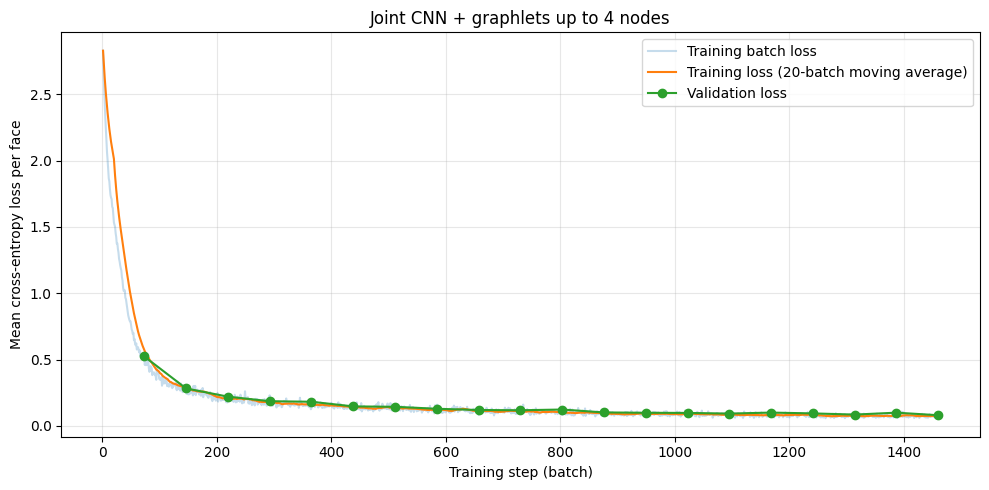

In [32]:
import matplotlib.pyplot as plt
import pandas as pd

batch_log = pd.DataFrame(batch_history)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(batch_log["step"], batch_log["loss"], alpha=0.25, label="Training batch loss")
ax.plot(batch_log["step"], batch_log["loss"].rolling(20, min_periods=1).mean(),
        label="Training loss (20-batch moving average)")
ax.plot([row["step"] for row in history],
        [row["validation_loss"] for row in history], marker="o", label="Validation loss")
ax.set_xlabel("Training step (batch)")
ax.set_ylabel("Mean cross-entropy loss per face")
ax.set_title(f"{training_mode.capitalize()} CNN + graphlets up to {max_graphlet_nodes} nodes")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(run_dir / "loss.png", dpi=150)
plt.show()


## Accuracy and IoU: baseline + graphlet variants

Compare final cached training and validation predictions for geometry only and graphlet sizes 2–4/2–5 with frozen/joint CNN. Shows epoch, loss, accuracy, unweighted mean IoU and per-class IoU. Missing runs are skipped. No inference or training.


In [33]:
# Compare cached final predictions across all completed variants.
from pathlib import Path
import json
import pandas as pd
import torch
from IPython.display import display
from uvnet_project.load_mfcad import DATA_DIR

project_dir = DATA_DIR.parent.parent
variant_dirs = {
    "Frozen CNN + graphlets 2–4": project_dir / "results/graphlet4_frozen_run_01",
    "Joint CNN + graphlets 2–4": project_dir / "results/graphlet4_joint_run_01",
    "Frozen CNN + graphlets 2–5": project_dir / "results/graphlet5_frozen_run_01",
    "Joint CNN + graphlets 2–5": project_dir / "results/graphlet5_joint_run_01",
    "Geometry only": project_dir / "results/baseline_run_01",
}
class_names = {}
for label_file in (DATA_DIR / "labels").glob("*.json"):
    with label_file.open() as file:
        faces = json.load(file)["body"]["faces"]
    for face in faces:
        segment = face["segment"]
        class_names[segment["index"]] = segment["name"]
    if len(class_names) == 16:
        break

summary_rows, class_rows = [], []
for variant, directory in variant_dirs.items():
    # Final predictions are written only after training. Use the highest epoch
    # with both splits available, not a partially written final evaluation.
    completed = [folder for folder in directory.glob("epoch_*")
                 if folder.name.removeprefix("epoch_").isdigit()
                 and all((folder / f"{split}_predictions.pt").is_file()
                         for split in ("train", "validation"))]
    if not completed:
        print(f"No completed prediction files yet: {variant}")
        continue
    checkpoint_dir = max(completed, key=lambda folder: int(folder.name.split("_")[-1]))
    epoch = int(checkpoint_dir.name.split("_")[-1])
    for split in ("train", "validation"):
        results = torch.load(checkpoint_dir / f"{split}_predictions.pt",
                             map_location="cpu", weights_only=True)
        labels, predictions = results["labels"].long(), results["predictions"].long()
        num_classes = results["probabilities"].shape[1]
        confusion = torch.bincount(labels * num_classes + predictions,
                                  minlength=num_classes**2).reshape(num_classes, num_classes)
        intersection = confusion.diag()
        support = confusion.sum(1)
        union = support + confusion.sum(0) - intersection
        iou = intersection.double() / union.double().masked_fill(union == 0, float("nan"))
        per_class_accuracy = intersection.double() / support.double().masked_fill(support == 0, float("nan"))
        summary_rows.append(dict(variant=variant, epoch=epoch, split=split,
                                 faces=labels.numel(), loss=results["loss"],
                                 accuracy=intersection.sum().item() / labels.numel(),
                                 mean_iou=iou.nanmean().item()))
        for index in range(num_classes):
            class_rows.append(dict(variant=variant, epoch=epoch, split=split,
                                   class_index=index, class_name=class_names.get(index, str(index)),
                                   support=support[index].item(), iou=iou[index].item(),
                                   accuracy=per_class_accuracy[index].item()))

if summary_rows:
    summary = pd.DataFrame(summary_rows).set_index(["variant", "epoch", "split"])
    per_class_metrics = pd.DataFrame(class_rows)
    display(summary.style.format({"loss": "{:.4f}", "accuracy": "{:.2%}", "mean_iou": "{:.2%}"}))
    print("Per-class IoU (unweighted class mean above, including stock):")
    display(per_class_metrics.pivot(index=["class_index", "class_name"],
                                    columns=["variant", "split"], values="iou").style.format("{:.2%}"))
    summary.to_csv(project_dir / "results/graphlet_variant_metrics.csv")
    per_class_metrics.to_csv(project_dir / "results/graphlet_variant_per_class_metrics.csv", index=False)
else:
    print("Run training through final prediction export before comparing metrics.")


Per-class IoU (unweighted class mean above, including stock):


## Loss comparison: baseline + graphlet variants

Read saved epoch-level training and validation losses for the geometry-only baseline and completed graphlet variants. Missing runs are skipped. Other model themes are excluded.


Saved comparison: /home/yongjun23/project/results/graphlet_variants_loss.png


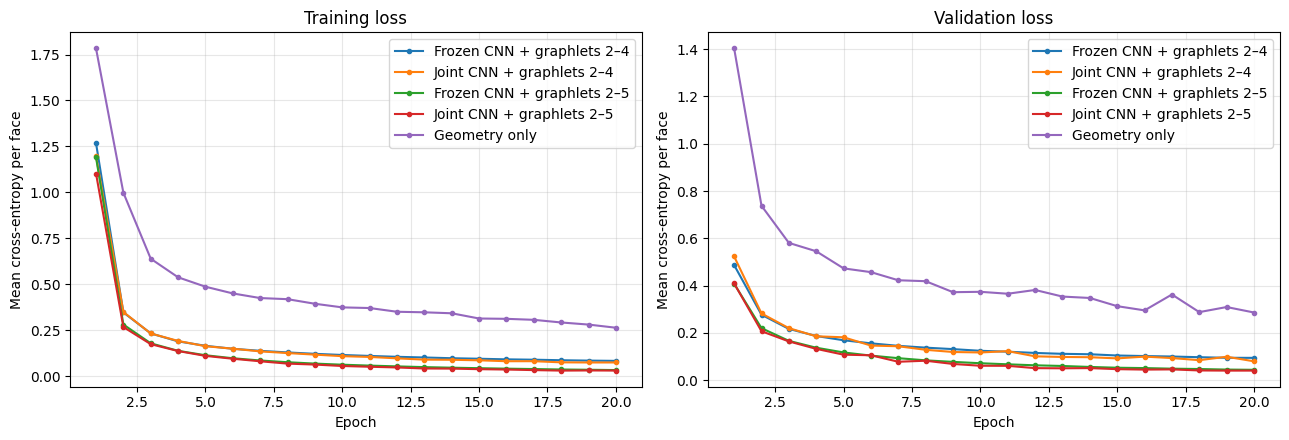

In [34]:
# Comparison from saved histories; no inference or training.
import matplotlib.pyplot as plt
import pandas as pd

variants = {
    "Frozen CNN + graphlets 2–4": project_dir / "results/graphlet4_frozen_run_01/history.csv",
    "Joint CNN + graphlets 2–4": project_dir / "results/graphlet4_joint_run_01/history.csv",
    "Frozen CNN + graphlets 2–5": project_dir / "results/graphlet5_frozen_run_01/history.csv",
    "Joint CNN + graphlets 2–5": project_dir / "results/graphlet5_joint_run_01/history.csv",
    "Geometry only": project_dir / "results/baseline_run_01/history.csv",
}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plotted = 0
for label, path in variants.items():
    if not path.is_file():
        print(f"Not run yet: {label}")
        continue
    frame = pd.read_csv(path)
    if frame.empty:
        continue
    for ax, metric in zip(axes, ("train_loss", "validation_loss")):
        ax.plot(frame["epoch"], frame[metric], marker="o", markersize=3, label=label)
    plotted += 1
for ax, title in zip(axes, ("Training loss", "Validation loss")):
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Mean cross-entropy per face")
    ax.grid(alpha=0.3)
    if plotted:
        ax.legend()
fig.tight_layout()
if plotted:
    comparison_path = project_dir / "results/graphlet_variants_loss.png"
    fig.savefig(comparison_path, dpi=150)
    print("Saved comparison:", comparison_path)
plt.show()
